# Calibration fit
Best-fit Heston vs market OTM implied vols on the 2026-11-10 calibration set.

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from heston.params import HestonParams
from heston.fft_pricer import fft_price_at
from calib.calibrate import S0, bs_vega
from calib.build_set import black76_iv

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
df = pd.read_csv(ROOT / "data" / "calib_set_20261110.csv", parse_dates=["expiry"])
p = HestonParams(v0=0.0338, kappa=8.137, vbar=0.0435, eta=1.961, rho=-0.706)
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]  # fixed categorical order
p

HestonParams(v0=0.0338, kappa=8.137, vbar=0.0435, eta=1.961, rho=-0.706)

## Model prices and implied vols
Puts via parity, like `calibrate.residuals`. Model IV is the Black-76 inversion with the same F, r, T.

In [4]:
parts = []
for expiry, g in df.groupby("expiry"):
    g = g.copy()
    T, r, q, F = g["T"].iloc[0], g.r.iloc[0], g.q.iloc[0], g.F.iloc[0]
    C = fft_price_at(g.K.values, S0, r, T, p, q)
    g["model"] = np.where(g.cp == "C", C, C - np.exp(-r * T) * (F - g.K))
    parts.append(g)
df = pd.concat(parts, ignore_index=True)

def iv_col(price_col):
    return [black76_iv(pr, F, K, T, r, cp)
            for pr, F, K, T, r, cp in zip(df[price_col], df.F, df.K, df["T"], df.r, df.cp)]

df["iv_model"] = iv_col("model")
df["iv_bid"] = iv_col("bid")
df["iv_ask"] = iv_col("ask")
df["moneyness"] = df.K / df.F
df["resid_vp"] = 100 * (df.iv_model - df.iv_own)
df["vega"] = bs_vega(df.F, df.K, df["T"], df.r, df.iv_own)
df["half_spread_vp"] = 100 * 0.5 * df.spread / df.vega
print(df[["iv_model", "iv_bid", "iv_ask"]].isna().sum())

iv_model    0
iv_bid      0
iv_ask      0
dtype: int64


## 1. Market vs model smile per expiry

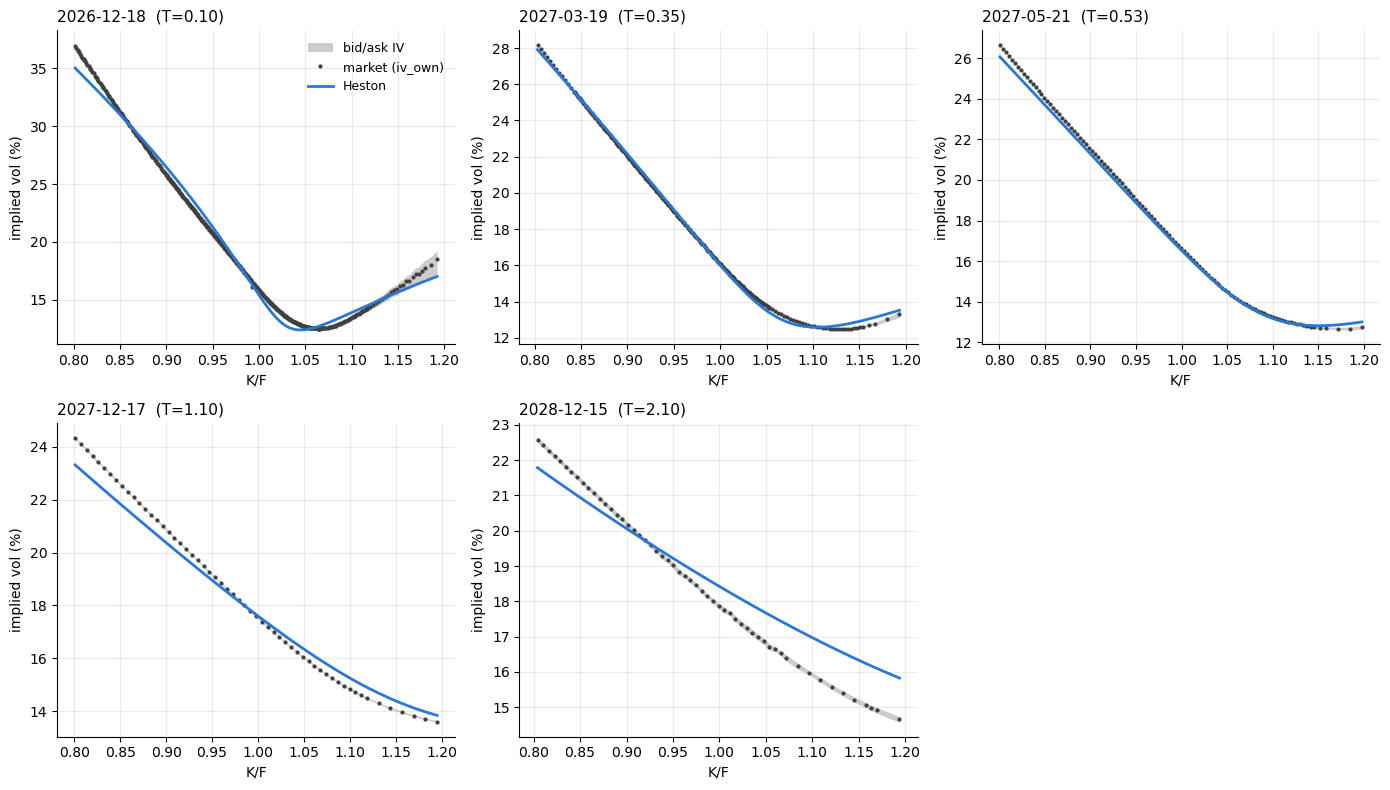

In [5]:
expiries = sorted(df.expiry.unique())
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, e in zip(axes.flat, expiries):
    g = df[df.expiry == e].sort_values("moneyness")
    ax.fill_between(g.moneyness, 100 * g.iv_bid, 100 * g.iv_ask, color="0.80", lw=0, label="bid/ask IV")
    ax.plot(g.moneyness, 100 * g.iv_own, ".", color="0.25", ms=4, label="market (iv_own)")
    ax.plot(g.moneyness, 100 * g.iv_model, color=COLORS[0], lw=2, label="Heston")
    ax.set_title(f"{pd.Timestamp(e).date()}  (T={g['T'].iloc[0]:.2f})", loc="left", fontsize=11)
    ax.set_xlabel("K/F"); ax.set_ylabel("implied vol (%)")
    ax.grid(alpha=0.25)
    for s in ("top", "right"): ax.spines[s].set_visible(False)
axes.flat[0].legend(frameon=False, fontsize=9)
axes.flat[-1].axis("off")
fig.tight_layout()
plt.show()

## 2. Residuals (model IV − market IV)

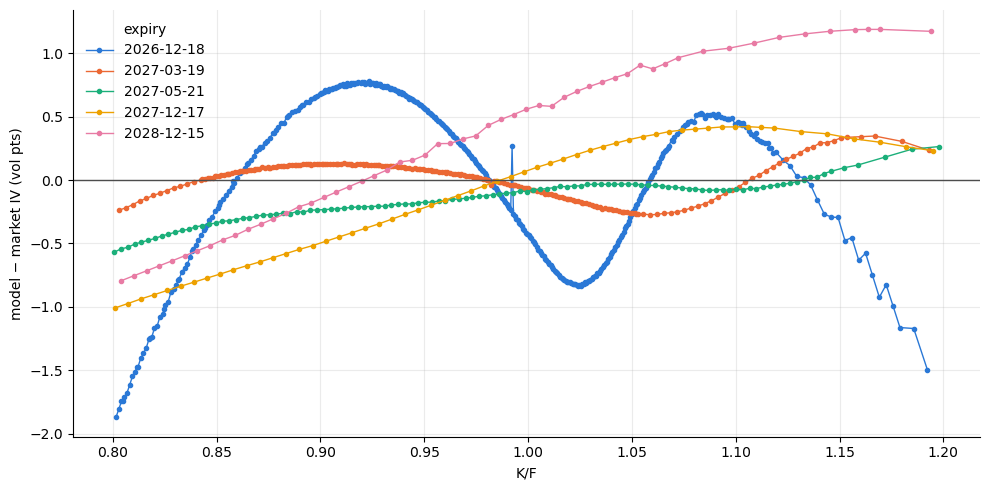

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
for color, e in zip(COLORS, expiries):
    g = df[df.expiry == e].sort_values("moneyness")
    ax.plot(g.moneyness, g.resid_vp, "o-", color=color, ms=3, lw=1, label=str(pd.Timestamp(e).date()))
ax.axhline(0, color="0.3", lw=1)
ax.set_xlabel("K/F"); ax.set_ylabel("model − market IV (vol pts)")
ax.grid(alpha=0.25)
for s in ("top", "right"): ax.spines[s].set_visible(False)
ax.legend(frameon=False, title="expiry")
fig.tight_layout()
plt.show()

## 3. Fit statistics per expiry (vol points)

In [7]:
stats = df.groupby(df.expiry.dt.date).agg(
    n=("resid_vp", "size"),
    rms_resid=("resid_vp", lambda x: np.sqrt(np.nanmean(x**2))),
    mean_resid=("resid_vp", "mean"),
    median_half_spread=("half_spread_vp", "median"),
)
all_row = pd.DataFrame({"n": [len(df)],
                        "rms_resid": [np.sqrt(np.nanmean(df.resid_vp**2))],
                        "mean_resid": [df.resid_vp.mean()],
                        "median_half_spread": [df.half_spread_vp.median()]}, index=["all"])
pd.concat([stats, all_row]).round(3)

,n,rms_resid,mean_resid,median_half_spread
2026-12-18,410,0.627,-0.019,0.071
2027-03-19,241,0.143,0.006,0.038
2027-05-21,112,0.224,-0.156,0.034
2027-12-17,57,0.487,-0.133,0.037
2028-12-15,55,0.691,0.298,0.073
all,875,0.491,-0.017,0.050
